### 0. Setup
Run once. Installs missing packages and downloads the NLTK resources only if they are not already present.

In [1]:
import importlib, subprocess, sys

required = {"nltk": "nltk", "sklearn": "scikit-learn", "textblob": "textblob",
            "wordcloud": "wordcloud", "tensorflow": "tensorflow",
            "pandas": "pandas", "matplotlib": "matplotlib"}
missing = [pip for mod, pip in required.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("All packages already installed.")

All packages already installed.


In [2]:
import nltk

NLTK_RESOURCES = {
    "punkt": "tokenizers/punkt",
    "punkt_tab": "tokenizers/punkt_tab",
    "stopwords": "corpora/stopwords",
    "wordnet": "corpora/wordnet",
    "omw-1.4": "corpora/omw-1.4",
    "vader_lexicon": "sentiment/vader_lexicon.zip",
    "averaged_perceptron_tagger_eng": "taggers/averaged_perceptron_tagger_eng",
}
for pkg, path in NLTK_RESOURCES.items():
    try:
        nltk.data.find(path)
    except LookupError:
        ok = nltk.download(pkg, quiet=True)
        print(f"downloaded {pkg}: {ok}")
print("NLTK resources ready.")

downloaded wordnet: True
downloaded omw-1.4: True
NLTK resources ready.


In [3]:
import re
import string
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords, wordnet
from nltk.probability import FreqDist
from nltk.stem import PorterStemmer, WordNetLemmatizer

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

STOP_WORDS = set(stopwords.words("english"))
print(f"{len(STOP_WORDS)} English stopwords loaded")

198 English stopwords loaded


---
## Q1. Text cleaning, tokenisation, stopwords & frequency distribution

**My paragraph (topic: compact SUVs in India).** It deliberately contains contractions (*it's, don't*), a number with a unit (*200 mm*), hyphenated words and commas so that the difference between `split()` and `word_tokenize()` is visible.

In [4]:
paragraph = (
    "Compact SUVs have quietly taken over Indian roads, and it's easy to see why. "
    "A petrol automatic SUV with 200 mm of ground clearance handles potholes, speed breakers "
    "and flooded underpasses far better than a low-slung sedan. "
    "Buyers today don't just compare mileage; they compare safety features, ADAS features, "
    "six airbags and connected-car features. "
    "Brands like Tata, Mahindra and Hyundai launch new SUV facelifts every two years because "
    "buyers keep asking for more features. "
    "However, real-world reliability, NVH levels and after-sales service still matter more "
    "than any spec sheet. "
    "For me, the perfect SUV feels refined in city traffic, stays quiet on the highway and "
    "never misses a service."
)
print(paragraph)
print(f"\nCharacters: {len(paragraph)}")

Compact SUVs have quietly taken over Indian roads, and it's easy to see why. A petrol automatic SUV with 200 mm of ground clearance handles potholes, speed breakers and flooded underpasses far better than a low-slung sedan. Buyers today don't just compare mileage; they compare safety features, ADAS features, six airbags and connected-car features. Brands like Tata, Mahindra and Hyundai launch new SUV facelifts every two years because buyers keep asking for more features. However, real-world reliability, NVH levels and after-sales service still matter more than any spec sheet. For me, the perfect SUV feels refined in city traffic, stays quiet on the highway and never misses a service.

Characters: 692


### Q1.1 Lowercase + remove punctuation with `re`
`[^\w\s]` matches every character that is **not** a word character or whitespace, i.e. all punctuation.

In [5]:
lower_text = paragraph.lower()
clean_text = re.sub(r"[^\w\s]", "", lower_text)     # strip punctuation
clean_text = re.sub(r"\s+", " ", clean_text).strip() # collapse extra spaces

print("Lowercased:\n", lower_text, "\n")
print("Lowercased + punctuation removed:\n", clean_text)

Lowercased:
 compact suvs have quietly taken over indian roads, and it's easy to see why. a petrol automatic suv with 200 mm of ground clearance handles potholes, speed breakers and flooded underpasses far better than a low-slung sedan. buyers today don't just compare mileage; they compare safety features, adas features, six airbags and connected-car features. brands like tata, mahindra and hyundai launch new suv facelifts every two years because buyers keep asking for more features. however, real-world reliability, nvh levels and after-sales service still matter more than any spec sheet. for me, the perfect suv feels refined in city traffic, stays quiet on the highway and never misses a service. 

Lowercased + punctuation removed:
 compact suvs have quietly taken over indian roads and its easy to see why a petrol automatic suv with 200 mm of ground clearance handles potholes speed breakers and flooded underpasses far better than a lowslung sedan buyers today dont just compare mileage 

### Q1.2 Word and sentence tokenisation
Sentence tokenisation is done on the **original** text because removing punctuation also removes the full stops that `sent_tokenize()` relies on to find sentence boundaries.

In [6]:
sentences = sent_tokenize(paragraph)
words = word_tokenize(clean_text)

print(f"Number of sentences: {len(sentences)}")
for i, s in enumerate(sentences, 1):
    print(f"  S{i}: {s}")

print(f"\nNumber of word tokens (cleaned text): {len(words)}")
print(words)

# what happens if we sentence-tokenise the cleaned text?
print(f"\nsent_tokenize on cleaned text -> {len(sent_tokenize(clean_text))} sentence(s)  (full stops are gone)")

Number of sentences: 6
  S1: Compact SUVs have quietly taken over Indian roads, and it's easy to see why.
  S2: A petrol automatic SUV with 200 mm of ground clearance handles potholes, speed breakers and flooded underpasses far better than a low-slung sedan.
  S3: Buyers today don't just compare mileage; they compare safety features, ADAS features, six airbags and connected-car features.
  S4: Brands like Tata, Mahindra and Hyundai launch new SUV facelifts every two years because buyers keep asking for more features.
  S5: However, real-world reliability, NVH levels and after-sales service still matter more than any spec sheet.
  S6: For me, the perfect SUV feels refined in city traffic, stays quiet on the highway and never misses a service.

Number of word tokens (cleaned text): 109
['compact', 'suvs', 'have', 'quietly', 'taken', 'over', 'indian', 'roads', 'and', 'its', 'easy', 'to', 'see', 'why', 'a', 'petrol', 'automatic', 'suv', 'with', '200', 'mm', 'of', 'ground', 'clearance', 'ha

### Q1.3 `str.split()` vs NLTK `word_tokenize()`
Both are applied to the **original** paragraph so the difference in punctuation handling is visible.

In [7]:
split_tokens = paragraph.split()
nltk_tokens = word_tokenize(paragraph)

print(f"split()          -> {len(split_tokens)} tokens")
print(f"word_tokenize()  -> {len(nltk_tokens)} tokens\n")

# Tokens that differ between the two methods
only_split = sorted(set(split_tokens) - set(nltk_tokens))
only_nltk = sorted(set(nltk_tokens) - set(split_tokens))

compare = pd.DataFrame({
    "Example word in text": ["roads,", "it's", "why.", "don't", "mileage;", "connected-car", "sedan."],
})
compare["split()"] = compare["Example word in text"].apply(lambda w: str(w.split()))
compare["word_tokenize()"] = compare["Example word in text"].apply(lambda w: str(word_tokenize(w)))
display(compare)

print("Tokens produced ONLY by split():        ", only_split)
print("Tokens produced ONLY by word_tokenize():", only_nltk)

split()          -> 109 tokens
word_tokenize()  -> 127 tokens



,Example word in text,split(),word_tokenize()
0,"roads,","['roads,']","['roads', ',']"
1,it's,"[""it's""]","['it', ""'s""]"
2,why.,['why.'],"['why', '.']"
3,don't,"[""don't""]","['do', ""n't""]"
4,mileage;,['mileage;'],"['mileage', ';']"
5,connected-car,['connected-car'],['connected-car']
6,sedan.,['sedan.'],"['sedan', '.']"


Tokens produced ONLY by split():         ['However,', 'Tata,', "don't", 'features,', 'features.', "it's", 'me,', 'mileage;', 'potholes,', 'reliability,', 'roads,', 'sedan.', 'service.', 'sheet.', 'traffic,', 'why.']
Tokens produced ONLY by word_tokenize(): ["'s", ',', '.', ';', 'However', 'Tata', 'do', 'features', 'it', 'me', 'mileage', "n't", 'potholes', 'reliability', 'roads', 'sedan', 'sheet', 'traffic', 'why']


**Observation.**

| Aspect | `str.split()` | `nltk.word_tokenize()` |
|---|---|---|
| Splits on | whitespace only | Treebank rules (punctuation, contractions) |
| Punctuation | stays glued to words (`roads,` `why.`) | separate tokens (`roads` `,`) |
| Contractions | kept whole (`don't`) | split into morphemes (`do` + `n't`, `it` + `'s`) |
| Hyphenated words | kept whole | kept whole (`connected-car`) |
| Token count | lower | higher (punctuation counted) |
| Use when | quick, already-clean text | any real NLP pipeline — vocabulary is not polluted by `why.` vs `why` |

`split()` would treat `why` and `why.` as two different vocabulary entries, which inflates the vocabulary and breaks frequency counts. `word_tokenize()` avoids that.

### Q1.4 Remove stopwords (NLTK list)

In [8]:
filtered_words = [w for w in words if w not in STOP_WORDS and w.isalpha()]
removed = [w for w in words if w in STOP_WORDS]
non_alpha = [w for w in words if not w.isalpha()]

print(f"Tokens before: {len(words)} | after stopword removal: {len(filtered_words)} | "
      f"stopwords removed: {len(removed)} | numeric tokens removed: {non_alpha}")
print("\nRemoved stopwords:", sorted(set(removed)))
print("\nRemaining tokens:", filtered_words)

Tokens before: 109 | after stopword removal: 77 | stopwords removed: 31 | numeric tokens removed: ['200']

Removed stopwords: ['a', 'and', 'any', 'because', 'for', 'have', 'in', 'its', 'just', 'me', 'more', 'of', 'on', 'over', 'than', 'the', 'they', 'to', 'why', 'with']

Remaining tokens: ['compact', 'suvs', 'quietly', 'taken', 'indian', 'roads', 'easy', 'see', 'petrol', 'automatic', 'suv', 'mm', 'ground', 'clearance', 'handles', 'potholes', 'speed', 'breakers', 'flooded', 'underpasses', 'far', 'better', 'lowslung', 'sedan', 'buyers', 'today', 'dont', 'compare', 'mileage', 'compare', 'safety', 'features', 'adas', 'features', 'six', 'airbags', 'connectedcar', 'features', 'brands', 'like', 'tata', 'mahindra', 'hyundai', 'launch', 'new', 'suv', 'facelifts', 'every', 'two', 'years', 'buyers', 'keep', 'asking', 'features', 'however', 'realworld', 'reliability', 'nvh', 'levels', 'aftersales', 'service', 'still', 'matter', 'spec', 'sheet', 'perfect', 'suv', 'feels', 'refined', 'city', 'traffi

### Q1.5 Word frequency distribution (excluding stopwords)

,Word,Frequency
0,features,4
1,suv,3
2,buyers,2
3,compare,2
4,service,2
5,compact,1
6,suvs,1
7,quietly,1
8,taken,1
9,indian,1


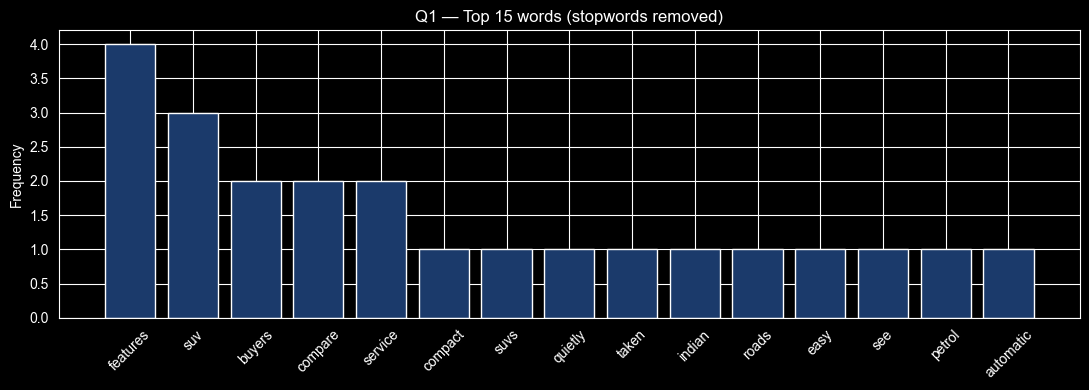

Vocabulary size (unique non-stopwords): 69
Hapax legomena (words that occur once): 64


In [9]:
fdist = FreqDist(filtered_words)
top = fdist.most_common(15)

freq_df = pd.DataFrame(top, columns=["Word", "Frequency"])
display(freq_df)

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(freq_df["Word"], freq_df["Frequency"], color="#1B3A6B")
ax.set_title("Q1 — Top 15 words (stopwords removed)")
ax.set_ylabel("Frequency")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

print(f"Vocabulary size (unique non-stopwords): {len(fdist)}")
print(f"Hapax legomena (words that occur once): {len(fdist.hapaxes())}")

---
## Q2. Regex extraction, stemming & lemmatisation (same paragraph)

### Q2.1 Extract alphabet-only words with `re.findall()`
`\b[a-zA-Z]+\b` keeps only tokens made purely of letters, so `200` is dropped. Contractions split at the apostrophe (`it's` → `it`, `s`).

In [10]:
alpha_words = re.findall(r"\b[a-zA-Z]+\b", paragraph.lower())
print(f"{len(alpha_words)} alphabetic tokens")
print(alpha_words)
print("\n'200' present?", "200" in alpha_words)

114 alphabetic tokens
['compact', 'suvs', 'have', 'quietly', 'taken', 'over', 'indian', 'roads', 'and', 'it', 's', 'easy', 'to', 'see', 'why', 'a', 'petrol', 'automatic', 'suv', 'with', 'mm', 'of', 'ground', 'clearance', 'handles', 'potholes', 'speed', 'breakers', 'and', 'flooded', 'underpasses', 'far', 'better', 'than', 'a', 'low', 'slung', 'sedan', 'buyers', 'today', 'don', 't', 'just', 'compare', 'mileage', 'they', 'compare', 'safety', 'features', 'adas', 'features', 'six', 'airbags', 'and', 'connected', 'car', 'features', 'brands', 'like', 'tata', 'mahindra', 'and', 'hyundai', 'launch', 'new', 'suv', 'facelifts', 'every', 'two', 'years', 'because', 'buyers', 'keep', 'asking', 'for', 'more', 'features', 'however', 'real', 'world', 'reliability', 'nvh', 'levels', 'and', 'after', 'sales', 'service', 'still', 'matter', 'more', 'than', 'any', 'spec', 'sheet', 'for', 'me', 'the', 'perfect', 'suv', 'feels', 'refined', 'in', 'city', 'traffic', 'stays', 'quiet', 'on', 'the', 'highway', 'and

### Q2.2 Remove stopwords
Single-letter fragments left by contractions (`s`, `t`) are already in NLTK's stopword list, so they disappear here too.

In [11]:
q2_tokens = [w for w in alpha_words if w not in STOP_WORDS]
print(f"{len(q2_tokens)} tokens after stopword removal")
print(q2_tokens)

79 tokens after stopword removal
['compact', 'suvs', 'quietly', 'taken', 'indian', 'roads', 'easy', 'see', 'petrol', 'automatic', 'suv', 'mm', 'ground', 'clearance', 'handles', 'potholes', 'speed', 'breakers', 'flooded', 'underpasses', 'far', 'better', 'low', 'slung', 'sedan', 'buyers', 'today', 'compare', 'mileage', 'compare', 'safety', 'features', 'adas', 'features', 'six', 'airbags', 'connected', 'car', 'features', 'brands', 'like', 'tata', 'mahindra', 'hyundai', 'launch', 'new', 'suv', 'facelifts', 'every', 'two', 'years', 'buyers', 'keep', 'asking', 'features', 'however', 'real', 'world', 'reliability', 'nvh', 'levels', 'sales', 'service', 'still', 'matter', 'spec', 'sheet', 'perfect', 'suv', 'feels', 'refined', 'city', 'traffic', 'stays', 'quiet', 'highway', 'never', 'misses', 'service']


### Q2.3 Stemming with `PorterStemmer`

In [12]:
stemmer = PorterStemmer()
stems = [stemmer.stem(w) for w in q2_tokens]
print(stems)

['compact', 'suv', 'quietli', 'taken', 'indian', 'road', 'easi', 'see', 'petrol', 'automat', 'suv', 'mm', 'ground', 'clearanc', 'handl', 'pothol', 'speed', 'breaker', 'flood', 'underpass', 'far', 'better', 'low', 'slung', 'sedan', 'buyer', 'today', 'compar', 'mileag', 'compar', 'safeti', 'featur', 'ada', 'featur', 'six', 'airbag', 'connect', 'car', 'featur', 'brand', 'like', 'tata', 'mahindra', 'hyundai', 'launch', 'new', 'suv', 'facelift', 'everi', 'two', 'year', 'buyer', 'keep', 'ask', 'featur', 'howev', 'real', 'world', 'reliabl', 'nvh', 'level', 'sale', 'servic', 'still', 'matter', 'spec', 'sheet', 'perfect', 'suv', 'feel', 'refin', 'citi', 'traffic', 'stay', 'quiet', 'highway', 'never', 'miss', 'servic']


### Q2.4 Lemmatisation with `WordNetLemmatizer`
Two versions are shown:
1. **Default** — `lemmatize(word)` assumes every word is a noun.
2. **POS-aware** — the POS tag from `nltk.pos_tag` is mapped to a WordNet tag, so verbs and adjectives are lemmatised correctly (e.g. *taken → take*, *flooded → flood*, *refined → refine*).

In [13]:
lemmatizer = WordNetLemmatizer()

def to_wordnet_pos(treebank_tag: str) -> str:
    if treebank_tag.startswith("J"):
        return wordnet.ADJ
    if treebank_tag.startswith("V"):
        return wordnet.VERB
    if treebank_tag.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN

lemmas_default = [lemmatizer.lemmatize(w) for w in q2_tokens]
tagged = nltk.pos_tag(q2_tokens)
lemmas_pos = [lemmatizer.lemmatize(w, to_wordnet_pos(t)) for w, t in tagged]

print("Default (noun) lemmas:\n", lemmas_default)
print("\nPOS-aware lemmas:\n", lemmas_pos)

Default (noun) lemmas:
 ['compact', 'suv', 'quietly', 'taken', 'indian', 'road', 'easy', 'see', 'petrol', 'automatic', 'suv', 'mm', 'ground', 'clearance', 'handle', 'pothole', 'speed', 'breaker', 'flooded', 'underpass', 'far', 'better', 'low', 'slung', 'sedan', 'buyer', 'today', 'compare', 'mileage', 'compare', 'safety', 'feature', 'ada', 'feature', 'six', 'airbags', 'connected', 'car', 'feature', 'brand', 'like', 'tata', 'mahindra', 'hyundai', 'launch', 'new', 'suv', 'facelift', 'every', 'two', 'year', 'buyer', 'keep', 'asking', 'feature', 'however', 'real', 'world', 'reliability', 'nvh', 'level', 'sale', 'service', 'still', 'matter', 'spec', 'sheet', 'perfect', 'suv', 'feel', 'refined', 'city', 'traffic', 'stay', 'quiet', 'highway', 'never', 'miss', 'service']

POS-aware lemmas:
 ['compact', 'suv', 'quietly', 'take', 'indian', 'road', 'easy', 'see', 'petrol', 'automatic', 'suv', 'mm', 'ground', 'clearance', 'handle', 'pothole', 'speed', 'breaker', 'flood', 'underpass', 'far', 'well',

### Q2.5 Compare stemmed vs lemmatised output

In [14]:
cmp = pd.DataFrame({
    "Original": q2_tokens,
    "POS": [t for _, t in tagged],
    "Porter stem": stems,
    "Lemma (default)": lemmas_default,
    "Lemma (POS-aware)": lemmas_pos,
})
cmp["Stem is a real word?"] = cmp["Porter stem"].apply(lambda s: "yes" if wordnet.synsets(s) else "no")

# only show rows where something actually changed
changed = cmp[(cmp["Original"] != cmp["Porter stem"]) | (cmp["Original"] != cmp["Lemma (POS-aware)"])]
display(changed.drop_duplicates("Original").reset_index(drop=True))

summary = pd.DataFrame({
    "Metric": ["Unique tokens", "Tokens changed", "Outputs that are not dictionary words"],
    "Original": [len(set(q2_tokens)), 0, sum(1 for w in set(q2_tokens) if not wordnet.synsets(w))],
    "Porter stem": [len(set(stems)),
                    sum(a != b for a, b in zip(q2_tokens, stems)),
                    sum(1 for w in set(stems) if not wordnet.synsets(w))],
    "Lemma (POS-aware)": [len(set(lemmas_pos)),
                          sum(a != b for a, b in zip(q2_tokens, lemmas_pos)),
                          sum(1 for w in set(lemmas_pos) if not wordnet.synsets(w))],
})
display(summary)

,Original,POS,Porter stem,Lemma (default),Lemma (POS-aware),Stem is a real word?
0,suvs,NN,suv,suv,suv,yes
1,quietly,RB,quietli,quietly,quietly,no
2,taken,VBN,taken,taken,take,yes
3,roads,NNS,road,road,road,yes
4,easy,JJ,easi,easy,easy,no
5,automatic,JJ,automat,automatic,automatic,yes
6,clearance,NN,clearanc,clearance,clearance,no
7,handles,VBZ,handl,handle,handle,no
8,potholes,NNS,pothol,pothole,pothole,no
9,breakers,NNS,breaker,breaker,breaker,yes


,Metric,Original,Porter stem,Lemma (POS-aware)
0,Unique tokens,71,70,70
1,Tokens changed,0,40,26
2,Outputs that are not dictionary words,5,20,5


**Stemming vs lemmatisation — when to prefer which**

| | Stemming (Porter) | Lemmatisation (WordNet) |
|---|---|---|
| Method | Rule-based suffix chopping | Dictionary lookup + POS |
| Output | Often not a real word (`quietli`, `easi`, `reliabl`, `servic`) | A valid dictionary form (`quietly`, `easy`, `take`, `service`) |
| Speed | Very fast, no dictionary | Slower, needs WordNet + ideally a POS tagger |
| Aggressiveness | High — merges more variants, sometimes wrongly | Conservative — only true inflections are merged |
| Context awareness | None | Uses POS (`taken`→`take` only when tagged as verb) |

**Prefer stemming** for large-scale search / information retrieval, spam filtering or Bag-of-Words classifiers where only matching word families matters, speed is important, and nobody reads the tokens.

**Prefer lemmatisation** when the output is read by humans or meaning matters — chatbots, question answering, topic labels, word clouds, knowledge extraction — and when the vocabulary is small enough that the extra cost is irrelevant. The summary table above makes this concrete: the stemmer turned many valid words into non-words, whereas the lemmatiser introduced none — its only non-dictionary outputs are the brand names and acronyms (`tata`, `nvh`, `mm`) that were already in the original text. The lemmatiser also merged `suvs`/`suv` and `features`/`feature` correctly while keeping them readable.

---
## Q3. Bag of Words & TF-IDF on 3 short texts
Three product reviews of different products, written by me.

In [15]:
docs = [
    "The new smartphone camera is brilliant in low light, and the battery easily lasts a full day. "
    "Charging is fast but the phone gets slightly warm while gaming.",
    "This mechanical keyboard feels amazing to type on. The tactile switches are crisp, the RGB "
    "lighting is subtle, and the keyboard software is surprisingly light.",
    "The noise cancelling headphones block traffic noise completely. Battery life is excellent, "
    "but the ear cushions get warm after two hours of music.",
]
doc_names = ["Doc1_Smartphone", "Doc2_Keyboard", "Doc3_Headphones"]
for n, d in zip(doc_names, docs):
    print(f"{n}: {d}\n")

Doc1_Smartphone: The new smartphone camera is brilliant in low light, and the battery easily lasts a full day. Charging is fast but the phone gets slightly warm while gaming.

Doc2_Keyboard: This mechanical keyboard feels amazing to type on. The tactile switches are crisp, the RGB lighting is subtle, and the keyboard software is surprisingly light.

Doc3_Headphones: The noise cancelling headphones block traffic noise completely. Battery life is excellent, but the ear cushions get warm after two hours of music.



### Q3.1 Bag of Words with `CountVectorizer`

In [16]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

count_vec = CountVectorizer(stop_words="english")
bow = count_vec.fit_transform(docs)

bow_df = pd.DataFrame(bow.toarray(), index=doc_names, columns=count_vec.get_feature_names_out())
print(f"BoW matrix shape: {bow.shape}  (documents x vocabulary)")
display(bow_df.T.sort_values(doc_names, ascending=False))

BoW matrix shape: (3, 42)  (documents x vocabulary)


,Doc1_Smartphone,Doc2_Keyboard,Doc3_Headphones
light,1,1,0
battery,1,0,1
warm,1,0,1
brilliant,1,0,0
camera,1,0,0
charging,1,0,0
day,1,0,0
easily,1,0,0
fast,1,0,0
gaming,1,0,0


### Q3.2 TF-IDF with `TfidfVectorizer`
Default sklearn settings: `idf = ln((1+n)/(1+df)) + 1` and each row is L2-normalised.

In [17]:
tfidf_vec = TfidfVectorizer(stop_words="english")
tfidf = tfidf_vec.fit_transform(docs)
vocab = tfidf_vec.get_feature_names_out()

tfidf_df = pd.DataFrame(tfidf.toarray(), index=doc_names, columns=vocab).round(3)
display(tfidf_df.T.sort_values(doc_names, ascending=False))

idf_df = pd.DataFrame({"term": vocab, "idf": tfidf_vec.idf_.round(3)}).sort_values("idf")
print("Lowest IDF terms (shared across documents):")
display(idf_df.head(5).reset_index(drop=True))

,Doc1_Smartphone,Doc2_Keyboard,Doc3_Headphones
brilliant,0.252,0.000,0.000
camera,0.252,0.000,0.000
charging,0.252,0.000,0.000
day,0.252,0.000,0.000
easily,0.252,0.000,0.000
fast,0.252,0.000,0.000
gaming,0.252,0.000,0.000
gets,0.252,0.000,0.000
lasts,0.252,0.000,0.000
low,0.252,0.000,0.000


Lowest IDF terms (shared across documents):


,term,idf
0,warm,1.288
1,battery,1.288
2,light,1.288
3,lighting,1.693
4,low,1.693


### Q3.3 Top 3 keywords per text

,Document,Rank,Keyword,TF-IDF,Count in doc,Docs containing term
0,Doc1_Smartphone,1,brilliant,0.252,1,1
1,Doc1_Smartphone,2,camera,0.252,1,1
2,Doc1_Smartphone,3,charging,0.252,1,1
3,Doc2_Keyboard,1,keyboard,0.491,2,1
4,Doc2_Keyboard,2,amazing,0.246,1,1
5,Doc2_Keyboard,3,crisp,0.246,1,1
6,Doc3_Headphones,1,noise,0.498,2,1
7,Doc3_Headphones,2,block,0.249,1,1
8,Doc3_Headphones,3,cancelling,0.249,1,1


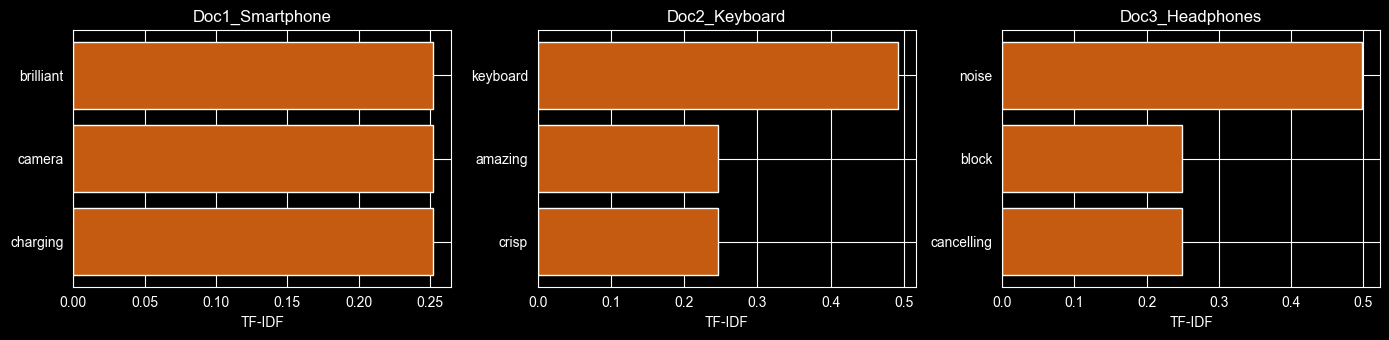

In [18]:
rows = []
for i, name in enumerate(doc_names):
    scores = tfidf[i].toarray().ravel()
    # sort by score (desc), break ties alphabetically so the result is deterministic
    top_idx = sorted(np.flatnonzero(scores), key=lambda j: (-scores[j], vocab[j]))[:3]
    for rank, j in enumerate(top_idx, 1):
        rows.append({"Document": name, "Rank": rank, "Keyword": vocab[j],
                     "TF-IDF": round(scores[j], 3),
                     "Count in doc": int(bow_df.loc[name, vocab[j]]),
                     "Docs containing term": int((bow_df[vocab[j]] > 0).sum())})
top3 = pd.DataFrame(rows)
display(top3)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, name in zip(axes, doc_names):
    sub = top3[top3["Document"] == name]
    ax.barh(sub["Keyword"][::-1], sub["TF-IDF"][::-1], color="#C55A11")
    ax.set_title(name)
    ax.set_xlabel("TF-IDF")
plt.tight_layout()
plt.show()

**Interpretation.**

- **Doc2 (keyboard)** — `keyboard` is the clear #1 because it appears **twice** and in no other review, so it gets both high TF and the maximum IDF. The remaining keywords are tied unique words; they describe the typing experience, which is exactly what this review is about.
- **Doc3 (headphones)** — `noise` appears twice and is unique to this document, so it ranks first; the next ones are unique single-occurrence terms tied on score.
- **Doc1 (smartphone)** — every content word appears only once, so all *unique* terms tie on TF-IDF; the top-3 are therefore unique product/feature words.
- **Words shared between reviews** (`battery`, `warm`, `light`) get a lower IDF, so they never reach the top-3 even though they are important for the product — TF-IDF rewards words that **distinguish** a document, not words that are merely frequent. This is why TF-IDF beats raw BoW counts for keyword extraction.
- Ties among single-occurrence unique terms are broken alphabetically; with texts this short TF-IDF cannot separate them, which is a real limitation of TF-IDF on short documents. Longer documents give more meaningful rankings.

---
## Q4. Jaccard vs Cosine similarity — AI vs Blockchain

In [19]:
text_ai = (
    "Artificial intelligence lets computers learn patterns from large amounts of data.\n"
    "Machine learning models are trained on data to make predictions and decisions.\n"
    "Deep learning uses neural networks with many layers to recognise images and speech.\n"
    "AI systems need powerful hardware and clean data to perform well.\n"
    "Today AI powers chatbots, recommendation engines and self-driving cars."
)
text_bc = (
    "Blockchain is a distributed ledger that records transactions across many computers.\n"
    "Each block stores data and a cryptographic hash of the previous block.\n"
    "Because the ledger is decentralised, no single authority controls the data.\n"
    "Consensus algorithms let the network agree on which transactions are valid.\n"
    "Today blockchain powers cryptocurrencies, smart contracts and supply chain tracking."
)
print("TEXT A — AI\n" + text_ai + "\n\nTEXT B — Blockchain\n" + text_bc)

TEXT A — AI
Artificial intelligence lets computers learn patterns from large amounts of data.
Machine learning models are trained on data to make predictions and decisions.
Deep learning uses neural networks with many layers to recognise images and speech.
AI systems need powerful hardware and clean data to perform well.
Today AI powers chatbots, recommendation engines and self-driving cars.

TEXT B — Blockchain
Blockchain is a distributed ledger that records transactions across many computers.
Each block stores data and a cryptographic hash of the previous block.
Because the ledger is decentralised, no single authority controls the data.
Consensus algorithms let the network agree on which transactions are valid.
Today blockchain powers cryptocurrencies, smart contracts and supply chain tracking.


### Q4.1 Preprocess and tokenise
Lowercase → strip punctuation with regex → `word_tokenize` → remove stopwords → POS-aware lemmatisation (so *computers/computer*, *transactions/transaction* match).

In [20]:
def preprocess(text: str) -> list[str]:
    text = re.sub(r"[^a-z\s]", " ", text.lower())
    tokens = [t for t in word_tokenize(text) if t not in STOP_WORDS and len(t) > 1]
    return [lemmatizer.lemmatize(w, to_wordnet_pos(tag)) for w, tag in nltk.pos_tag(tokens)]

tok_ai = preprocess(text_ai)
tok_bc = preprocess(text_bc)
print(f"AI tokens ({len(tok_ai)}):\n{tok_ai}\n")
print(f"Blockchain tokens ({len(tok_bc)}):\n{tok_bc}")

AI tokens (45):
['artificial', 'intelligence', 'let', 'computer', 'learn', 'pattern', 'large', 'amount', 'data', 'machine', 'learning', 'model', 'train', 'data', 'make', 'prediction', 'decision', 'deep', 'learning', 'use', 'neural', 'network', 'many', 'layer', 'recognise', 'image', 'speech', 'ai', 'system', 'need', 'powerful', 'hardware', 'clean', 'data', 'perform', 'well', 'today', 'ai', 'power', 'chatbots', 'recommendation', 'engine', 'self', 'drive', 'car']

Blockchain tokens (37):
['blockchain', 'distribute', 'ledger', 'record', 'transaction', 'across', 'many', 'computer', 'block', 'store', 'data', 'cryptographic', 'hash', 'previous', 'block', 'ledger', 'decentralise', 'single', 'authority', 'control', 'data', 'consensus', 'algorithm', 'let', 'network', 'agree', 'transaction', 'valid', 'today', 'blockchain', 'power', 'cryptocurrencies', 'smart', 'contract', 'supply', 'chain', 'track']


### Q4.2(a) Jaccard similarity using sets
$$J(A,B)=\frac{|A\cap B|}{|A\cup B|}$$

In [21]:
set_ai, set_bc = set(tok_ai), set(tok_bc)
intersection = set_ai & set_bc
union = set_ai | set_bc
jaccard = len(intersection) / len(union) if union else 0.0

print(f"|A| = {len(set_ai)}, |B| = {len(set_bc)}")
print(f"|A ∩ B| = {len(intersection)} -> {sorted(intersection)}")
print(f"|A ∪ B| = {len(union)}")
print(f"\nJaccard similarity = {len(intersection)}/{len(union)} = {jaccard:.4f}")

|A| = 41, |B| = 32
|A ∩ B| = 7 -> ['computer', 'data', 'let', 'many', 'network', 'power', 'today']
|A ∪ B| = 66

Jaccard similarity = 7/66 = 0.1061


### Q4.2(b) Cosine similarity using `TfidfVectorizer` + `cosine_similarity()`
$$\cos(\theta)=\frac{\vec a\cdot\vec b}{\lVert\vec a\rVert\,\lVert\vec b\rVert}$$

In [22]:
from sklearn.metrics.pairwise import cosine_similarity

pair_vec = TfidfVectorizer()
pair_tfidf = pair_vec.fit_transform([" ".join(tok_ai), " ".join(tok_bc)])
cosine = cosine_similarity(pair_tfidf[0], pair_tfidf[1])[0, 0]

shared_terms = pd.DataFrame(pair_tfidf.toarray(), index=["AI", "Blockchain"],
                            columns=pair_vec.get_feature_names_out()).T
shared_terms = shared_terms[(shared_terms["AI"] > 0) & (shared_terms["Blockchain"] > 0)].round(3)
shared_terms["product (contribution)"] = (shared_terms["AI"] * shared_terms["Blockchain"]).round(4)
display(shared_terms.sort_values("product (contribution)", ascending=False))

# Same metric on raw text (no preprocessing) for comparison
raw_vec = TfidfVectorizer()
raw = raw_vec.fit_transform([text_ai, text_bc])
cosine_raw = cosine_similarity(raw[0], raw[1])[0, 0]

print(f"Cosine similarity (preprocessed TF-IDF) = {cosine:.4f}")
print(f"Cosine similarity (raw text TF-IDF)     = {cosine_raw:.4f}  <- inflated by shared stopwords")

,AI,Blockchain,product (contribution)
data,0.309,0.219,0.0677
computer,0.103,0.110,0.0113
let,0.103,0.110,0.0113
many,0.103,0.110,0.0113
network,0.103,0.110,0.0113
power,0.103,0.110,0.0113
today,0.103,0.110,0.0113


Cosine similarity (preprocessed TF-IDF) = 0.1358
Cosine similarity (raw text TF-IDF)     = 0.1510  <- inflated by shared stopwords


### Q4.2(c) Which metric gives better insight here?

,Metric,Score,Uses frequency?,Uses term importance (IDF)?
0,Jaccard (sets),0.1061,No,No
1,"Cosine (TF-IDF, preprocessed)",0.1358,Yes,Yes
2,"Cosine (TF-IDF, raw text)",0.1510,Yes,Yes


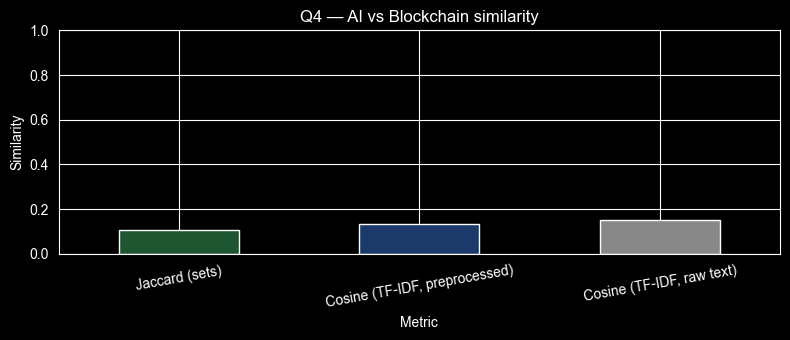

In [23]:
results = pd.DataFrame({
    "Metric": ["Jaccard (sets)", "Cosine (TF-IDF, preprocessed)", "Cosine (TF-IDF, raw text)"],
    "Score": [round(jaccard, 4), round(cosine, 4), round(cosine_raw, 4)],
    "Uses frequency?": ["No", "Yes", "Yes"],
    "Uses term importance (IDF)?": ["No", "Yes", "Yes"],
})
display(results)

ax = results.plot.bar(x="Metric", y="Score", legend=False, color=["#1E5631", "#1B3A6B", "#888888"], figsize=(8, 3.5))
ax.set_ylim(0, 1); ax.set_ylabel("Similarity"); ax.set_title("Q4 — AI vs Blockchain similarity")
plt.xticks(rotation=10); plt.tight_layout(); plt.show()

**Analysis.**

1. Both metrics agree that the two texts are **largely dissimilar**, which is correct — AI and blockchain are different technologies whose descriptions only overlap on 7 generic words (`computer`, `data`, `let`, `many`, `network`, `power`, `today`). Note that `network` is shared by accident — *neural network* vs *peer-to-peer network* — something no bag-of-words metric can detect.
2. **Jaccard** only asks *"is the word present?"*. Every shared word counts equally, so a vague word like `today` contributes exactly as much as a technical word would. It also ignores that `data` is repeated several times in the AI text — repetition is a signal of what the text is about.
3. **Cosine on TF-IDF** weighs each term by how often it occurs (TF) and how distinctive it is (IDF), and length-normalises the vectors. With only two documents, words present in both get a lower IDF, so shared generic words are automatically down-weighted, and the frequent `data` term contributes the most (see the contribution table).
4. Preprocessing matters as much as the metric: cosine on **raw** text is inflated because both texts share `the`, `and`, `of`, `to`. After stopword removal and lemmatisation the score reflects actual topical overlap.

**Verdict:** **Cosine similarity with TF-IDF gives the better insight in this case** — it explains *why* the texts overlap (via term weights), handles repeated terms and texts of different lengths, and scales to comparing many documents. Jaccard is still useful as a quick, interpretable vocabulary-overlap check (e.g. near-duplicate detection or comparing tag sets) where frequency doesn't matter.

---
## Q5. Sentiment analysis (TextBlob + VADER) and word cloud
Short reviews of a food-delivery app, written by me. Several reviews are used so that the Positive / Negative / Neutral classification and the positive-review word cloud are meaningful.

In [24]:
reviews = [
    "The app is fantastic! Food arrived hot, ten minutes early, and the delivery partner was really polite.",
    "Terrible experience. My order was cancelled after an hour and the refund still hasn't come.",
    "Great discounts on weekends and the live tracking is super accurate. Totally worth the membership.",
    "The order arrived at 8 pm. I paid using UPI.",
    "Customer support was slow and rude, and half the items were missing from my bag.",
    "Loved the clean interface and quick checkout. The biryani was delicious and well packed.",
    "Delivery was average, the food was okay but a little cold.",
]
print(f"{len(reviews)} reviews")

7 reviews


### Q5.1 Polarity & subjectivity
- **TextBlob**: `polarity` ∈ [-1, 1], `subjectivity` ∈ [0, 1] (0 = objective fact, 1 = personal opinion).
- **VADER**: `compound` ∈ [-1, 1]; handles intensifiers, capitalisation, `!` and negation, tuned for short informal text. VADER has no subjectivity score, so subjectivity comes from TextBlob.

In [25]:
from textblob import TextBlob
from nltk.sentiment import SentimentIntensityAnalyzer

vader = SentimentIntensityAnalyzer()

def label_from_score(score: float, threshold: float) -> str:
    if score >= threshold:
        return "Positive"
    if score <= -threshold:
        return "Negative"
    return "Neutral"

records = []
for i, r in enumerate(reviews, 1):
    tb = TextBlob(r).sentiment
    vs = vader.polarity_scores(r)
    records.append({
        "ID": f"R{i}",
        "Review": r,
        "TB polarity": round(tb.polarity, 3),
        "TB subjectivity": round(tb.subjectivity, 3),
        "VADER neg": vs["neg"], "VADER neu": vs["neu"], "VADER pos": vs["pos"],
        "VADER compound": vs["compound"],
    })
sent_df = pd.DataFrame(records)
display(sent_df)

,ID,Review,TB polarity,TB subjectivity,VADER neg,VADER neu,VADER pos,VADER compound
0,R1,"The app is fantastic! Food arrived hot, ten mi...",0.210,0.450,0.000,0.804,0.196,0.5983
1,R2,Terrible experience. My order was cancelled af...,-1.000,1.000,0.282,0.718,0.000,-0.6249
2,R3,Great discounts on weekends and the live track...,0.394,0.530,0.000,0.541,0.459,0.8805
3,R4,The order arrived at 8 pm. I paid using UPI.,0.000,0.000,0.000,1.000,0.000,0.0000
4,R5,"Customer support was slow and rude, and half t...",-0.242,0.304,0.261,0.603,0.136,-0.3612
5,R6,Loved the clean interface and quick checkout. ...,0.600,0.750,0.000,0.446,0.554,0.9081
6,R7,"Delivery was average, the food was okay but a ...",-0.109,0.600,0.000,0.861,0.139,0.1154


### Q5.2 Classify into Positive / Negative / Neutral
Thresholds: VADER `compound ≥ 0.05` → Positive, `≤ -0.05` → Negative, else Neutral (the threshold recommended by VADER's authors). TextBlob uses ±0.1 on polarity. **VADER is used as the final label** because it is designed for short, informal reviews.

,ID,Review,TB polarity,TB subjectivity,VADER compound,TextBlob label,VADER label,Agree?
0,R1,"The app is fantastic! Food arrived hot, ten mi...",0.210,0.450,0.5983,Positive,Positive,yes
1,R2,Terrible experience. My order was cancelled af...,-1.000,1.000,-0.6249,Negative,Negative,yes
2,R3,Great discounts on weekends and the live track...,0.394,0.530,0.8805,Positive,Positive,yes
3,R4,The order arrived at 8 pm. I paid using UPI.,0.000,0.000,0.0000,Neutral,Neutral,yes
4,R5,"Customer support was slow and rude, and half t...",-0.242,0.304,-0.3612,Negative,Negative,yes
5,R6,Loved the clean interface and quick checkout. ...,0.600,0.750,0.9081,Positive,Positive,yes
6,R7,"Delivery was average, the food was okay but a ...",-0.109,0.600,0.1154,Negative,Positive,no


Final label
Positive    4
Neutral     1
Negative    2

TextBlob and VADER agree on 6/7 reviews


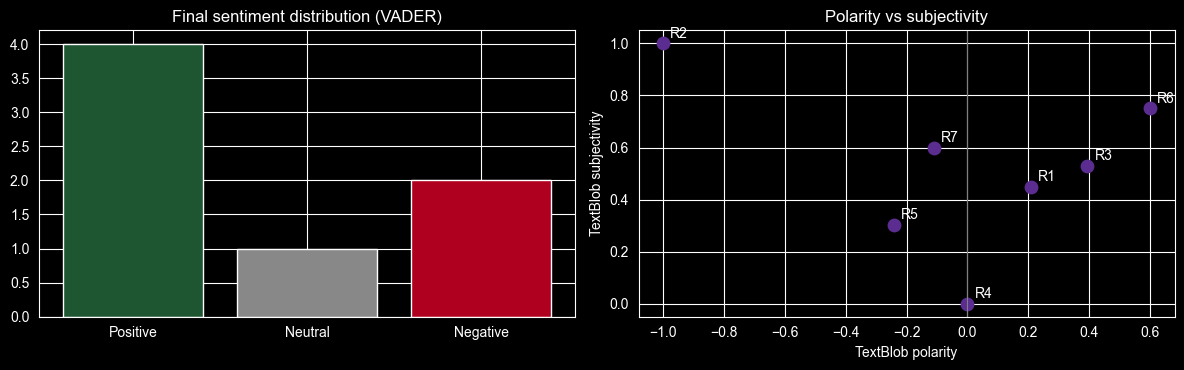

In [26]:
sent_df["TextBlob label"] = sent_df["TB polarity"].apply(lambda s: label_from_score(s, 0.10))
sent_df["VADER label"] = sent_df["VADER compound"].apply(lambda s: label_from_score(s, 0.05))
sent_df["Final label"] = sent_df["VADER label"]
sent_df["Agree?"] = np.where(sent_df["TextBlob label"] == sent_df["VADER label"], "yes", "no")

display(sent_df[["ID", "Review", "TB polarity", "TB subjectivity", "VADER compound",
                 "TextBlob label", "VADER label", "Agree?"]])

counts = sent_df["Final label"].value_counts().reindex(["Positive", "Neutral", "Negative"], fill_value=0)
print(counts.to_string())
print(f"\nTextBlob and VADER agree on {(sent_df['Agree?'] == 'yes').sum()}/{len(sent_df)} reviews")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(counts.index, counts.values, color=["#1E5631", "#888888", "#B00020"])
axes[0].set_title("Final sentiment distribution (VADER)")
axes[1].scatter(sent_df["TB polarity"], sent_df["TB subjectivity"], s=80, color="#5C2D91")
for _, row in sent_df.iterrows():
    axes[1].annotate(row["ID"], (row["TB polarity"], row["TB subjectivity"]), xytext=(5, 4), textcoords="offset points")
axes[1].axvline(0, color="grey", lw=0.8)
axes[1].set_xlabel("TextBlob polarity"); axes[1].set_ylabel("TextBlob subjectivity")
axes[1].set_title("Polarity vs subjectivity")
plt.tight_layout(); plt.show()

### Q5.3 Word cloud of all positive reviews

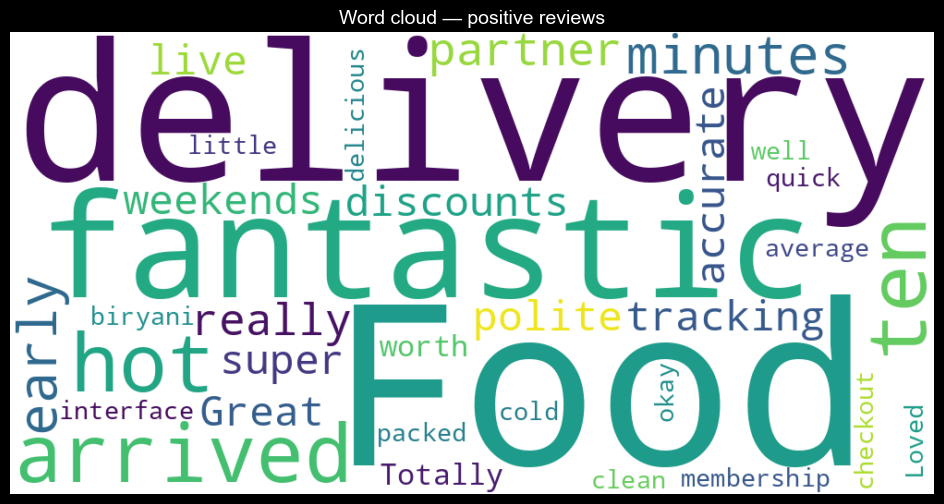

Saved: q5_positive_wordcloud.png
Top words: [('Food', 1.0), ('delivery', 1.0), ('fantastic', 0.5), ('arrived', 0.5), ('hot', 0.5), ('ten', 0.5), ('minutes', 0.5), ('early', 0.5), ('partner', 0.5), ('really', 0.5)]


In [27]:
from wordcloud import WordCloud, STOPWORDS as WC_STOPWORDS

positive_text = " ".join(sent_df.loc[sent_df["Final label"] == "Positive", "Review"])
if not positive_text.strip():
    print("No positive reviews found — nothing to plot.")
else:
    wc_stop = set(WC_STOPWORDS) | STOP_WORDS | {"app", "order"}
    wc = WordCloud(width=1000, height=500, background_color="white", colormap="viridis",
                   stopwords=wc_stop, max_words=60, random_state=42).generate(positive_text)
    plt.figure(figsize=(12, 6))
    plt.imshow(wc, interpolation="bilinear")
    plt.axis("off")
    plt.title("Word cloud — positive reviews", fontsize=14)
    plt.show()
    wc.to_file("q5_positive_wordcloud.png")
    print("Saved: q5_positive_wordcloud.png")
    print("Top words:", sorted(wc.words_.items(), key=lambda kv: -kv[1])[:10])

**Observations.**
- The purely factual review (*"The order arrived at 8 pm. I paid using UPI."*) has polarity 0 and subjectivity 0 in TextBlob and compound 0 in VADER → correctly **Neutral** and objective.
- Strongly opinionated reviews have high subjectivity (close to 1) regardless of whether they are positive or negative — subjectivity measures *how opinionated*, polarity measures *which direction*.
- The only disagreement is **R7** (*"average… okay but a little cold"*): VADER scores it mildly positive (compound ≈ +0.12, driven by *okay*), TextBlob mildly negative (polarity ≈ −0.11, driven by *cold* and *little*). A human would call it **neutral/mixed**, so the VADER label is arguably wrong here. Lexicon-based tools add up word scores and struggle with mixed or sarcastic sentences; a fine-tuned transformer would be the next step for production use.
- The word cloud surfaces what customers actually praise — speed, food quality, discounts, tracking and the interface.

---
## Q6. Text generation with an LSTM (Keras)
**Training paragraph (~100 words, written by me, topic: learning competitive programming).**

In [28]:
import os, random
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import tensorflow as tf

try:                                    # TF 2.x bundled Keras
    from tensorflow.keras.preprocessing.text import Tokenizer
except ImportError:                     # standalone legacy Keras 2
    from tf_keras.preprocessing.text import Tokenizer
from tensorflow.keras.utils import pad_sequences, to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Dropout

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("TensorFlow", tf.__version__)

corpus = (
    "competitive programming taught me to think before i type. "
    "every problem starts with reading the constraints carefully. "
    "the constraints tell you which algorithm will pass and which will fail. "
    "a brute force idea is a good start but it rarely passes the time limit. "
    "so i learn to spot patterns like two pointers, binary search and dynamic programming. "
    "dynamic programming feels hard at first but it becomes natural with practice. "
    "practice every day and solve problems slightly above your level. "
    "when a solution fails, read the editorial, understand the idea and write the code again. "
    "consistent practice turns hard problems into familiar patterns."
)
print(f"Words in corpus: {len(corpus.split())}")

TensorFlow 2.21.0
Words in corpus: 103


### Q6.1 Tokenise with `Tokenizer()`

In [29]:
tokenizer = Tokenizer(oov_token="<OOV>")
lines = [l.strip() for l in corpus.split(".") if l.strip()]   # one training line per sentence
tokenizer.fit_on_texts(lines)

vocab_size = len(tokenizer.word_index) + 1   # +1 for padding index 0
print(f"Training lines: {len(lines)}")
print(f"Vocabulary size (incl. padding): {vocab_size}")
print("First 20 entries of word_index:", dict(list(tokenizer.word_index.items())[:20]))
print("\nLine 1 as integers:", tokenizer.texts_to_sequences([lines[0]])[0])

Training lines: 9
Vocabulary size (incl. padding): 77
First 20 entries of word_index: {'<OOV>': 1, 'the': 2, 'and': 3, 'programming': 4, 'a': 5, 'practice': 6, 'to': 7, 'i': 8, 'every': 9, 'with': 10, 'constraints': 11, 'which': 12, 'will': 13, 'idea': 14, 'but': 15, 'it': 16, 'patterns': 17, 'dynamic': 18, 'hard': 19, 'problems': 20}

Line 1 as integers: [21, 4, 22, 23, 7, 24, 25, 8, 26]


### Q6.2 Create n-gram input sequences and build an LSTM model
Every line `w1 w2 … wn` produces prefixes `[w1,w2]`, `[w1,w2,w3]`, … ; the last word of each prefix is the label and the rest (left-padded) is the input.

In [30]:
input_sequences = []
for line in lines:
    ids = tokenizer.texts_to_sequences([line])[0]
    for i in range(1, len(ids)):
        input_sequences.append(ids[: i + 1])

max_len = max(len(s) for s in input_sequences)
input_sequences = pad_sequences(input_sequences, maxlen=max_len, padding="pre")
X, y_ids = input_sequences[:, :-1], input_sequences[:, -1]
y = to_categorical(y_ids, num_classes=vocab_size)

print(f"Number of training sequences: {len(input_sequences)}")
print(f"Max sequence length: {max_len}  -> X shape {X.shape}, y shape {y.shape}")

example = pd.DataFrame({
    "Input (words)": [" ".join(tokenizer.index_word.get(t, "") for t in row if t) for row in X[:6]],
    "Target word": [tokenizer.index_word[t] for t in y_ids[:6]],
})
display(example)

Number of training sequences: 94
Max sequence length: 15  -> X shape (94, 14), y shape (94, 77)


,Input (words),Target word
0,competitive,programming
1,competitive programming,taught
2,competitive programming taught,me
3,competitive programming taught me,to
4,competitive programming taught me to,think
5,competitive programming taught me to think,before


In [31]:
model = Sequential([
    Input(shape=(max_len - 1,)),
    Embedding(input_dim=vocab_size, output_dim=64),
    LSTM(150),
    Dropout(0.1),
    Dense(vocab_size, activation="softmax"),
])
model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 14, 64)         │         4,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 150)            │       129,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 150)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 77)             │        11,627 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 145,555 (568.57 KB)

 Trainable params: 145,555 (568.57 KB)

 Non-trainable params: 0 (0.00 B)

### Q6.3 Train the model

In [ ]:
history = model.fit(X, y, epochs=250, batch_size=16, verbose=0)

final_loss, final_acc = history.history["loss"][-1], history.history["accuracy"][-1]
print(f"Final training loss: {final_loss:.4f} | final training accuracy: {final_acc:.2%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(history.history["loss"], color="#B00020"); axes[0].set_title("Training loss"); axes[0].set_xlabel("epoch")
axes[1].plot(history.history["accuracy"], color="#1E5631"); axes[1].set_title("Training accuracy"); axes[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

### Generate new lines from seed words
- **Greedy** decoding picks the most probable next word each step (deterministic, tends to replay training text).
- **Temperature sampling** (T = 1.5) samples from the softmax distribution, so it can combine phrases from different sentences into new lines.

In [ ]:
def generate(seed: str, n_words: int = 10, temperature: float | None = None) -> str:
    text = seed.lower().strip()
    for _ in range(n_words):
        ids = tokenizer.texts_to_sequences([text])[0]
        ids = pad_sequences([ids], maxlen=max_len - 1, padding="pre")
        probs = model.predict(ids, verbose=0)[0].astype("float64")
        probs[0] = 0.0                                   # never emit padding
        probs[tokenizer.word_index["<OOV>"]] = 0.0        # never emit <OOV>
        if temperature is None:
            next_id = int(np.argmax(probs))
        else:
            logits = np.log(probs + 1e-9) / temperature
            p = np.exp(logits - logits.max()); p /= p.sum()
            next_id = int(np.random.choice(len(p), p=p))
        text += " " + tokenizer.index_word[next_id]
    return text

np.random.seed(SEED)
seeds = ["practice", "dynamic", "a solution"]
gen_rows = []
for s in seeds:
    gen_rows.append({"Seed": s, "Decoding": "greedy", "Generated line": generate(s, 10)})
    gen_rows.append({"Seed": s, "Decoding": "sampling T=1.5", "Generated line": generate(s, 10, temperature=1.5)})
gen_df = pd.DataFrame(gen_rows)
display(gen_df)

print("Generated lines:")
for _, r in gen_df.iterrows():
    print(f"  [{r['Decoding']:>14}] {r['Generated line']}")

**Discussion.**
- With only ~100 words of training data the LSTM essentially **memorises** the paragraph — training accuracy approaches 100%, so greedy decoding mostly reproduces training phrases. That is expected; there is no validation data and the goal here is to demonstrate the pipeline.
- Temperature sampling flattens the softmax so lower-probability words get chosen occasionally, letting the model jump between sentences that share a word (*practice*, *problems*, *solution*, *idea*) and produce lines that do not appear verbatim in the paragraph. Because the model is extremely confident after memorising the data, even T = 1.5 often follows the training text.
- Seeds that never start a training sentence (e.g. *a solution*) force the model into unseen contexts, which is where the most "creative" (and least grammatical) output appears.
- To get genuinely novel, grammatical text: train on a much larger corpus, hold out validation data with early stopping, use a word-level embedding pre-trained on general text, or move to a character-level / transformer model.

---
## Summary
| Q | What was done | Key result |
|---|---|---|
| 1 | Regex cleaning, word/sentence tokenisation, `split()` vs `word_tokenize()`, stopwords, `FreqDist` | `word_tokenize` separates punctuation and contractions; frequency plot of content words |
| 2 | `re.findall`, stopwords, Porter stemming, WordNet lemmatisation (default + POS-aware) | Stems are often non-words; POS-aware lemmas are always valid words |
| 3 | `CountVectorizer` BoW, `TfidfVectorizer`, top-3 keywords | TF-IDF ranks distinctive terms above shared ones |
| 4 | Jaccard (sets) vs Cosine (TF-IDF) for AI vs Blockchain | Both show low similarity; cosine + TF-IDF is more informative |
| 5 | TextBlob + VADER polarity/subjectivity, 3-class labels, word cloud | Reviews classified; word cloud of positive reviews |
| 6 | Keras `Tokenizer`, n-gram sequences, Embedding → LSTM → Dense, generation | Model trained and new lines generated from 3 seeds |